# Overview

# The Question: How do we make reliable yes/no predictions when the outcome is uncertain, the data are messy, and the boundary between classes may be simple or complex?

# Techniques we will use:

## 1. How do we turn a linear score into a probability?

### Logistic regression and the sigmoid function.

## 2. How do we judge how good or bad predicted probabilities are?

### Cross-entropy / log loss.

## 3. What goes wrong when we have too many predictors and too little data?

### Overfitting and unstable coefficients.

## 4. How do lasso and ridge regression help with that?

### Regularization.

## 5. Why must we scale features before regularization?

### Fair penalties across variables.  (E.g. imagine height in feet and weight in pounds are features.  Which might have bigger coefficients?)

## 6. What if we care more about classification boundaries than probabilities?

### SVMs.

## 7. What if the boundary is nonlinear?

### Kernel SVMs.

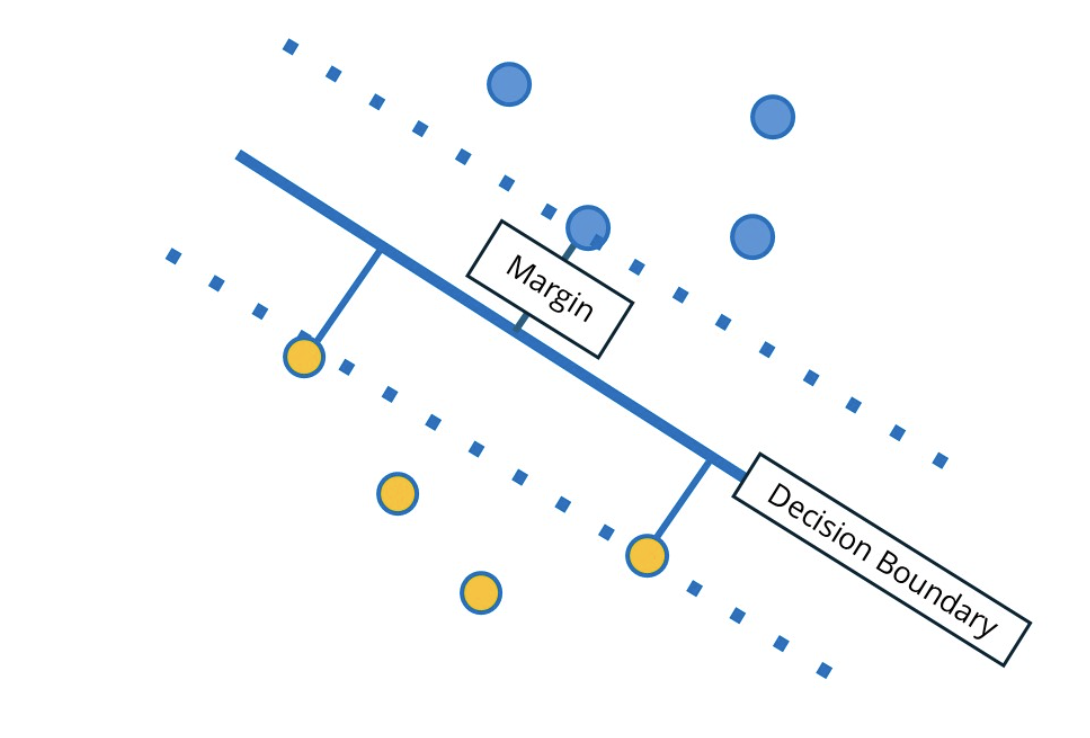

In [36]:
from IPython.display import Image, display

display(Image(filename="Screenshot 2.png"))

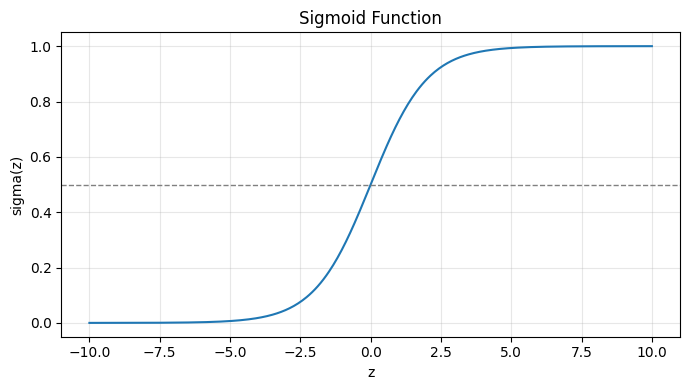

In [16]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))
# Plot sigmoid
z = np.linspace(-10, 10, 400)
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel("z")
plt.ylabel("sigma(z)")
plt.title("Sigmoid Function")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Story 1: The Space Shuttle Challenger O-ring disaster

On the night of January 27, 1986, the night before the space shuttle Challenger accident, there was a three-hour teleconference among people at Morton Thiokol (manufacturer of the solid rocket motor), Marshall Space Flight
Center, and Kennedy Space Center. The discussion focused on the forecast of a 31 F temperature for launch time the next morning, and the effect of low temperature on O-ring performance. A data set played an important role in the discussion. Based on the U configuration of points (identified by the flight number), it was concluded that there was no evidence from the historical data about a temperature effect.
 
NASA launched the Space Shuttle Challenger on January 28, 1986, in unusually cold weather. The shuttle broke apart shortly after launch, killing all seven crew members. A key failure involved the rubber O-rings in the solid rocket boosters, which in fact were sensitive to temperature.

Where logistic regression enters: After the disaster, statisticians analyzed previous shuttle launch data using models including logistic regression. The binary outcome was something like:

Did an O-ring show damage/distress? Yes or no.

Of the two candidates, pressure and temperature, the main predictor was launch temperature.

The intuitive finding was clear: colder launch temperatures were associated with much higher probability of O-ring damage. Challenger launched at about 31°F, colder than previous launches. A logistic regression model on prior launch data suggested that this was an extremely dangerous regime.

This is a case where the predictor was easy to understand, and the stakes were life and death. The tragedy is that the relevant data existed, but the risk was not communicated effectively enough before launch.

Source:

Dalal, S. R., Fowlkes, E. B., & Hoadley, B. “Risk Analysis of the Space Shuttle: Pre-Challenger Prediction of Failure.” Journal of the American Statistical Association, 1989.

https://doi.org/10.1080/01621459.1989.10478858

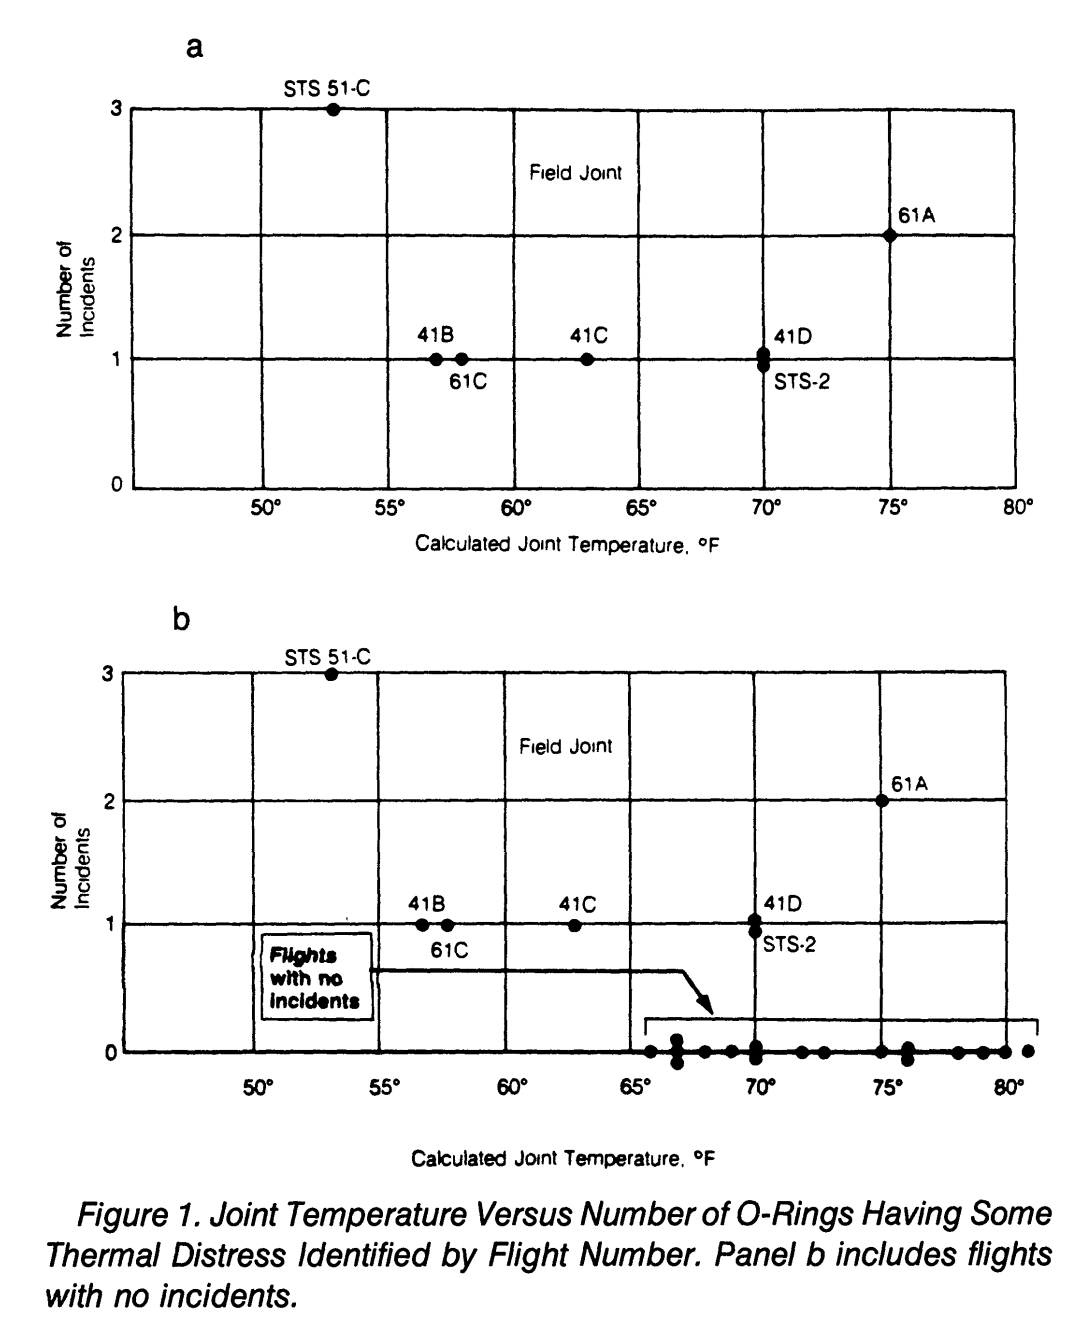

In [13]:
from IPython.display import Image, display

display(Image(filename="Screenshot 1.png"))

## Core Idea:

Logistic regression estimates

$$P(y = True | x)$$

By computing a linear score:

$$z = \beta_0 x_0 + \beta_1 x_1 + \ldots + \beta_p x_p$$

And converting it to a probability:

$$\frac{1}{1 + \exp(-z)}$$

## Why this matters:

Logistic regression is useful when the decision is binary but the risk is gradual. O-ring damage is not simply “safe” or “unsafe”; the probability of damage changes with temperature.

In various applications:

Will an O-ring show damage?

Will a patient develop disease?

Will a customer churn?

Will a loan default?

## Data 1.a, two feature logistic regression:

This is a synthetic O-ring dataset with observations containing temperature, pressure, and a binary damage indicator. The data are designed so that the probability of O-ring damage increases as temperature decreases, with 50°F representing low temperature and 80°F representing high temperature. Pressure is also included as a possible explanatory variable.

Its similarity to the Challenger explosion is that the Challenger disaster involved concerns about O-ring performance at unusually low launch temperatures. In both cases, the key idea is modeling the probability of O-ring damage as a function of environmental conditions, especially temperature. The logistic regression reflects the same kind of question: as temperature drops, does the probability of O-ring failure or damage increase?

        temp     pressure  damage
0  52.289249  2517.248640       1
1  73.397564  2651.369214       1
2  63.152277  2070.158107       1
3  71.703955  2936.567771       1
4  79.339685  2224.191397       0

================ LOGISTIC REGRESSION SUMMARY ================

                           Logit Regression Results                           
Dep. Variable:                 damage   No. Observations:                 1200
Model:                          Logit   Df Residuals:                     1197
Method:                           MLE   Df Model:                            2
Date:                Thu, 11 Jun 2026   Pseudo R-squ.:                  0.2636
Time:                        13:24:08   Log-Likelihood:                -476.54
converged:                       True   LL-Null:                       -647.13
Covariance Type:            nonrobust   LLR p-value:                 8.163e-75
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------

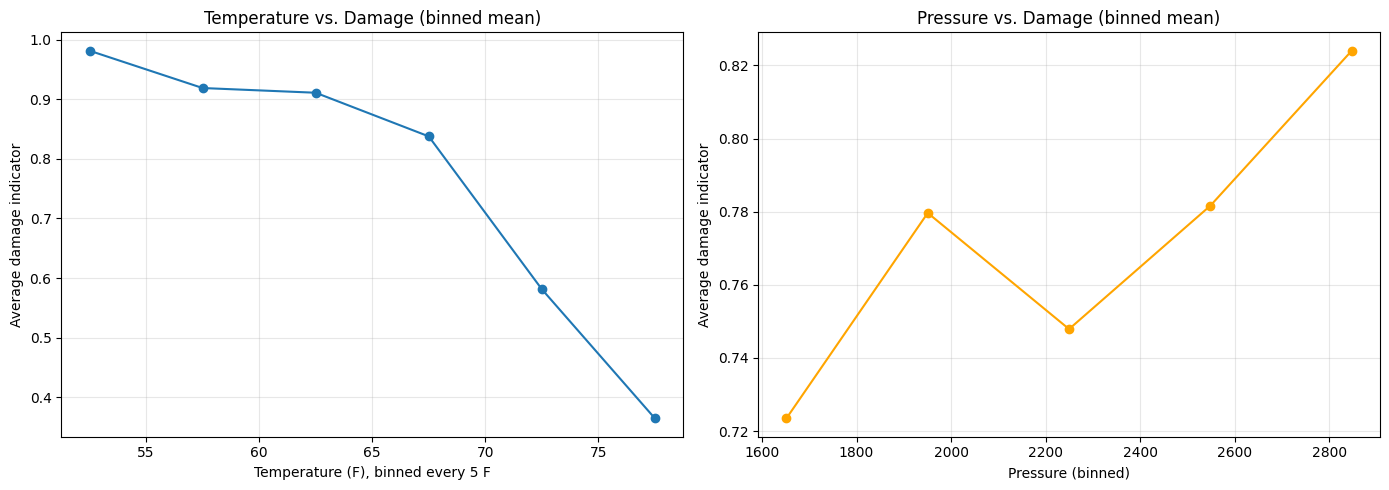

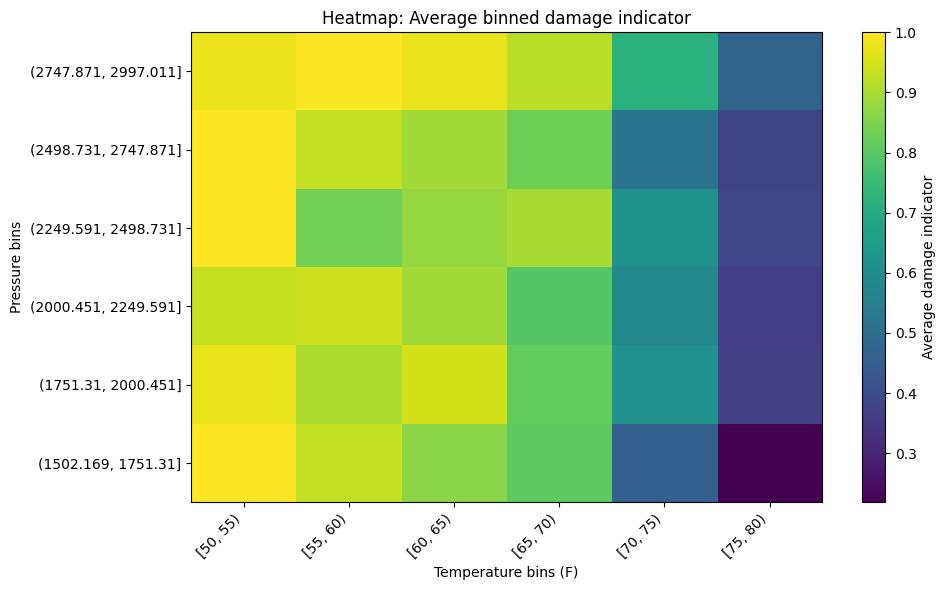

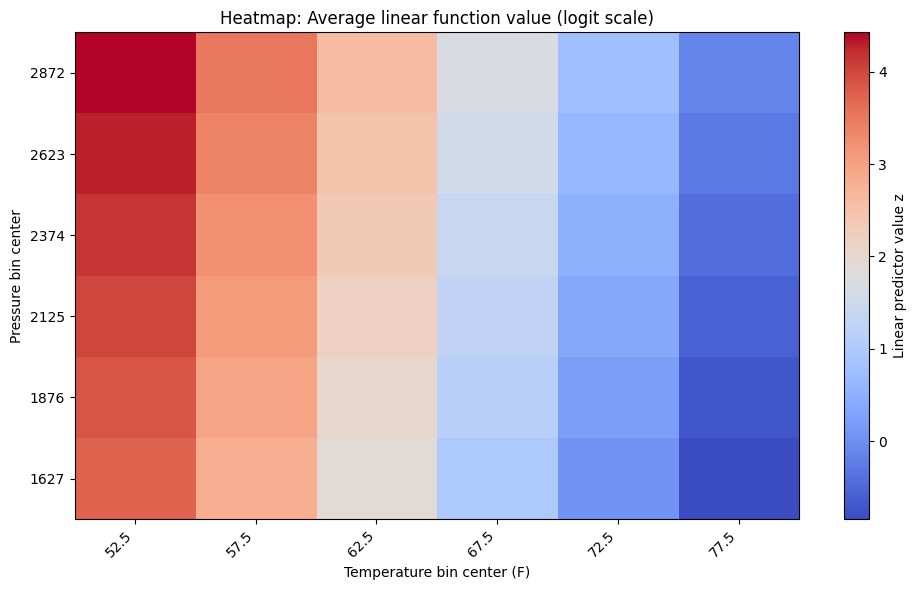

In [18]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# -----------------------------
# 1) Synthetic O-ring data
# -----------------------------
np.random.seed(7)

n = 1200

# Temperature: 50 F = low, 80 F = high
temp = np.random.uniform(50, 80, size=n)

# Pressure: synthetic, moderate range
pressure = np.random.uniform(1500, 3000, size=n)

# True data-generating process:
# lower temperature -> higher damage probability
# higher pressure -> slightly higher damage probability
# (chosen so the logistic regression has a reasonable signal)
beta_0 = 10.5
beta_temp = -0.17
beta_pressure = 0.0010

linear_true = beta_0 + beta_temp * temp + beta_pressure * pressure
p_damage = 1 / (1 + np.exp(-linear_true))
damage = np.random.binomial(1, p_damage, size=n)

df = pd.DataFrame({
    "temp": temp,
    "pressure": pressure,
    "damage": damage
})

print(df.head())

# -----------------------------
# 2) Logistic regression in statsmodels
# -----------------------------
X = sm.add_constant(df[["temp", "pressure"]])
y = df["damage"]

logit_model = sm.Logit(y, X)
result = logit_model.fit(disp=False)

print("\n================ LOGISTIC REGRESSION SUMMARY ================\n")
print(result.summary())

# -----------------------------
# 3) Print fitted logistic equation
# -----------------------------
b0 = result.params["const"]
b1 = result.params["temp"]
b2 = result.params["pressure"]

print("\n================ FITTED LOGISTIC EQUATION ================\n")
print(
    "p(damage=1 | temp, pressure) = 1 / (1 + exp(-z))\n"
    f"where z = ({b0:.6f}) + ({b1:.6f})*temp + ({b2:.6f})*pressure"
)

# -----------------------------
# 4) Binned plots: temp vs damage, pressure vs damage
#    Bin width = 5 F for temperature
#    For pressure, use 5 equal-width bins for a similar binned-average plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Temp bins every 5 F
temp_bins = np.arange(50, 85, 5)  # 50,55,...,80
df["temp_bin"] = pd.cut(df["temp"], bins=temp_bins, include_lowest=True, right=False)
temp_binned = df.groupby("temp_bin", observed=False)["damage"].mean().reset_index()

temp_bin_centers = []
for interval in temp_binned["temp_bin"]:
    temp_bin_centers.append((interval.left + interval.right) / 2)

axes[0].plot(temp_bin_centers, temp_binned["damage"], marker="o")
axes[0].set_xlabel("Temperature (F), binned every 5 F")
axes[0].set_ylabel("Average damage indicator")
axes[0].set_title("Temperature vs. Damage (binned mean)")
axes[0].grid(True, alpha=0.3)

# Pressure bins: 5 bins
pressure_bins = np.linspace(df["pressure"].min(), df["pressure"].max(), 6)
df["pressure_bin"] = pd.cut(df["pressure"], bins=pressure_bins, include_lowest=True)
pressure_binned = df.groupby("pressure_bin", observed=False)["damage"].mean().reset_index()

pressure_bin_centers = []
for interval in pressure_binned["pressure_bin"]:
    pressure_bin_centers.append((interval.left + interval.right) / 2)

axes[1].plot(pressure_bin_centers, pressure_binned["damage"], marker="o", color="orange")
axes[1].set_xlabel("Pressure (binned)")
axes[1].set_ylabel("Average damage indicator")
axes[1].set_title("Pressure vs. Damage (binned mean)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# -----------------------------
# 5) Heatmap 1:
#    Average binned damage indicator on temp vs pressure
# -----------------------------
temp_edges = np.arange(50, 85, 5)  # 50-55, ..., 75-80
pressure_edges = np.linspace(df["pressure"].min(), df["pressure"].max(), 7)

df["temp_bin2"] = pd.cut(df["temp"], bins=temp_edges, include_lowest=True, right=False)
df["pressure_bin2"] = pd.cut(df["pressure"], bins=pressure_edges, include_lowest=True)

damage_pivot = df.pivot_table(
    index="pressure_bin2",
    columns="temp_bin2",
    values="damage",
    aggfunc="mean"
)

# Order the axes in increasing numeric order
damage_pivot = damage_pivot.sort_index(axis=0).sort_index(axis=1)

plt.figure(figsize=(10, 6))
im1 = plt.imshow(
    damage_pivot.values,
    aspect="auto",
    origin="lower",
    cmap="viridis",
    interpolation="nearest"
)
plt.colorbar(im1, label="Average damage indicator")
plt.xticks(
    ticks=np.arange(len(damage_pivot.columns)),
    labels=[str(c) for c in damage_pivot.columns],
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(damage_pivot.index)),
    labels=[str(i) for i in damage_pivot.index]
)
plt.xlabel("Temperature bins (F)")
plt.ylabel("Pressure bins")
plt.title("Heatmap: Average binned damage indicator")
plt.tight_layout()
plt.show()

# -----------------------------
# 6) Heatmap 2:
#    Average linear function value z = b0 + b1*temp + b2*pressure
#    on the same temp vs pressure grid
# -----------------------------
# Use bin centers to evaluate linear predictor
temp_centers = np.array([(interval.left + interval.right) / 2 for interval in damage_pivot.columns])
pressure_centers = np.array([(interval.left + interval.right) / 2 for interval in damage_pivot.index])

z_grid = np.zeros((len(pressure_centers), len(temp_centers)))
for i, p in enumerate(pressure_centers):
    for j, t in enumerate(temp_centers):
        z_grid[i, j] = b0 + b1 * t + b2 * p

plt.figure(figsize=(10, 6))
im2 = plt.imshow(
    z_grid,
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
    interpolation="nearest"
)
plt.colorbar(im2, label="Linear predictor value z")
plt.xticks(
    ticks=np.arange(len(temp_centers)),
    labels=[f"{c:.1f}" for c in temp_centers],
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(pressure_centers)),
    labels=[f"{c:.0f}" for c in pressure_centers]
)
plt.xlabel("Temperature bin center (F)")
plt.ylabel("Pressure bin center")
plt.title("Heatmap: Average linear function value (logit scale)")
plt.tight_layout()
plt.show()

In [7]:
123638/931

132.8012889366273

In [13]:
import numpy as np
z = -10
1 / (1 + np.exp(-z))

np.float64(4.5397868702434395e-05)

In [4]:
import numpy as np
1 / (1 + np.exp(-3)), 1 / (1 + np.exp(1))

(np.float64(0.9525741268224334), np.float64(0.2689414213699951))

In [8]:
import numpy as np
z = 2
print(np.exp(-z))
print(1 + np.exp(-z))
print(1 / (1 + np.exp(-z)))

0.1353352832366127
1.1353352832366128
0.8807970779778823


In [ ]:
1 / (1 + np.exp(-(intercept + beta_pressure * pressure + beta_temperature * temperature)))

In [17]:
1 / (1 + np.exp(-(10.49 - 0.1698 * 52.5 + 0.000997 * 2300))), 1 / (1 + np.exp(-(10.49 - 0.1698 * 77.5 + 0.000997 * 2300)))

(np.float64(0.9795397732667529), np.float64(0.4069954658806659))

In [24]:
z = -3
print(np.exp(-z))
print(1 + np.exp(-z))
print(1 / (1 + np.exp(-z)))

20.085536923187668
21.085536923187668
0.04742587317756678


In [15]:
result.params

const       10.493916
temp        -0.169816
pressure     0.000997
dtype: float64

The Challenger example shows why probability estimates matter. But logistic regression can become unstable when we have many predictors and only a small amount of data. That leads to the next question: how do we stop a model from fitting noise?

# Data 1.b, twenty feature logistic regression with lasso and ridge:

We are creating synthetic binary-classification data with 80 rows and 40 features, where only one feature truly affects the target and the rest are noise. We fit logistic regression models using three approaches: unregularized cross-entropy, lasso, and ridge. To avoid overly optimistic results, we split the data into training and test sets and report test accuracy and log loss for samples of size 20, 40, and 80. The goal is to see how model performance changes as more data become available, and how regularization helps when the signal is weak and most features are irrelevant.

Sigmoid equation:
sigma(z) = 1 / (1 + exp(-z))

Cross-entropy loss equation (binary):
L = - (1/n) * sum_i [ y_i * log(p_i) + (1 - y_i) * log(1 - p_i) ]

Cross-entropy matters because accuracy alone ignores confidence. A model that predicts 0.51 and is correct is different from a model that predicts 0.99 and is correct. Likewise, a confidently wrong prediction should be punished more heavily than a mildly wrong prediction.


Lasso loss equation:
L_lasso = cross_entropy_loss + lambda * sum_j |beta_j|

Ridge loss equation:
L_ridge = cross_entropy_loss + lambda * sum_j beta_j^2

Regularization matters because real datasets often contain too many predictors relative to the number of observations. Without regularization, the model may memorize noise and perform poorly on new data.



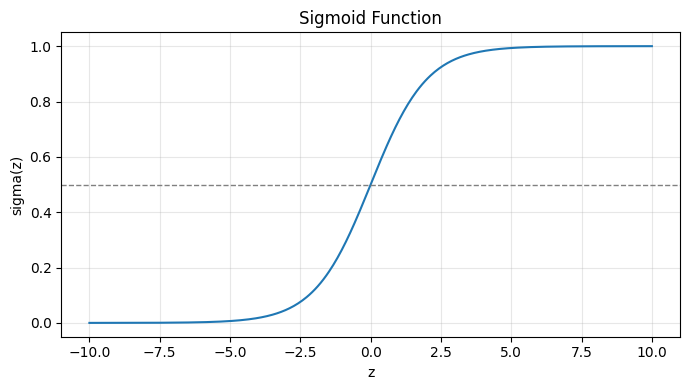


Synthetic dataset created:
- Rows: 80
- Columns/features: 40
- Only feature 0 truly affects the target; the others are noise.

Fitted cross-entropy equation using 20 rows:
p = 1 / (1 + exp(-z)), where z = 3.2237 + (7.8856)*x1 + (0.7548)*x2 + (-0.8202)*x3 + (-0.3490)*x4 + (2.0095)*x5 + (-3.8288)*x6 + (-1.9993)*x7 + (-2.1354)*x8 + (1.8283)*x9 + (-0.3163)*x10 + (-0.2574)*x11 + (1.8504)*x12 + (-1.0601)*x13 + (1.1162)*x14 + (2.5521)*x15 + (2.8428)*x16 + (0.5595)*x17 + (-0.0875)*x18 + (-0.6215)*x19 + (-0.4398)*x20 + (1.4018)*x21 + (1.7567)*x22 + (2.7628)*x23 + (-1.5133)*x24 + (1.8392)*x25 + (1.8118)*x26 + (-4.5185)*x27 + (-1.4066)*x28 + (1.4137)*x29 + (4.2145)*x30 + (2.0471)*x31 + (4.4388)*x32 + (0.1799)*x33 + (-0.0097)*x34 + (3.0661)*x35 + (-1.0389)*x36 + (1.1255)*x37 + (-1.9472)*x38 + (-4.7715)*x39 + (-1.0478)*x40

Fitted lasso equation using 20 rows:
p = 1 / (1 + exp(-z)), where z = 0.0000 + (1.8076)*x1 + (0.0000)*x2 + (0.0000)*x3 + (0.0000)*x4 + (0.0000)*x5 + (-0.8634)*x6 + (0.0000)*x7 

/Users/vonkorff/jupyter-classic/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/vonkorff/jupyter-classic/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/vonkorff/jupyter-classic/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/vonkorff/jupyter-classic/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, para

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss
from sklearn.preprocessing import StandardScaler

# ============================================================
# Adjustable settings
# ============================================================
row_counts = [20, 40, 80]
n_rows = 80
n_features = 40
random_state = 42

np.random.seed(random_state)

# ============================================================
# 1) Sigmoid function and equations
# ============================================================
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("Sigmoid equation:")
print("sigma(z) = 1 / (1 + exp(-z))")

print("\nCross-entropy loss equation (binary):")
print("L = - (1/n) * sum_i [ y_i * log(p_i) + (1 - y_i) * log(1 - p_i) ]")

text = "Cross-entropy matters because accuracy alone ignores confidence. A model that predicts 0.51 and is correct is different from a model that predicts 0.99 and is correct. Likewise, a confidently wrong prediction should be punished more heavily than a mildly wrong prediction."
print(f"\n{text}\n")

print("\nLasso loss equation:")
print("L_lasso = cross_entropy_loss + lambda * sum_j |beta_j|")

print("\nRidge loss equation:")
print("L_ridge = cross_entropy_loss + lambda * sum_j beta_j^2")

text2 = "Regularization matters because real datasets often contain too many predictors relative to the number of observations. Without regularization, the model may memorize noise and perform poorly on new data."
print(f"\n{text2}\n")

# Plot sigmoid
z = np.linspace(-10, 10, 400)
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel("z")
plt.ylabel("sigma(z)")
plt.title("Sigmoid Function")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 2) Synthetic data
#    Only one feature truly affects the binary target
#    Make the signal weaker to avoid perfect separation
# ============================================================
X = np.random.normal(size=(n_rows, n_features))

true_beta = np.zeros(n_features)
true_beta[0] = 5.0
intercept = 0.0

linear_part = intercept + X @ true_beta + np.random.normal(scale=1.5, size=n_rows)
p = sigmoid(linear_part)
y = np.random.binomial(1, p, size=n_rows)

print("\nSynthetic dataset created:")
print(f"- Rows: {n_rows}")
print(f"- Columns/features: {n_features}")
print("- Only feature 0 truly affects the target; the others are noise.")

# ============================================================
# 3) Fit models using train/test split
#    Cross-entropy: statsmodels GLM Binomial
#    Lasso / Ridge: statsmodels regularized GLM
# ============================================================
results = []

for n_fit in row_counts:
    X_sub = X[:n_fit]
    y_sub = y[:n_fit]

    # If one class only appears, skip this setting
    if len(np.unique(y_sub)) < 2:
        print(f"\nSkipping n={n_fit} because only one class is present.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(
        X_sub,
        y_sub,
        test_size=0.3,
        random_state=random_state,
        stratify=y_sub
    )

    # Standardize using training data only
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    X_train_sm = sm.add_constant(X_train_scaled, has_constant="add")
    X_test_sm = sm.add_constant(X_test_scaled, has_constant="add")

    # -----------------------------
    # Cross-entropy / unregularized
    # -----------------------------
    ce_model = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())
    ce_fit = ce_model.fit()
    ce_prob = ce_fit.predict(X_test_sm)
    ce_pred = (ce_prob >= 0.5).astype(int)
    ce_acc = accuracy_score(y_test, ce_pred)
    ce_ll = log_loss(y_test, ce_prob)

    # -----------------------------
    # Lasso (L1)
    # -----------------------------
    # alpha controls regularization strength
    lasso_model = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())
    lasso_fit = lasso_model.fit_regularized(alpha=0.05, L1_wt=1.0, maxiter=1000)
    lasso_prob = lasso_fit.predict(X_test_sm)
    lasso_pred = (lasso_prob >= 0.5).astype(int)
    lasso_acc = accuracy_score(y_test, lasso_pred)
    lasso_ll = log_loss(y_test, lasso_prob)

    # -----------------------------
    # Ridge (L2)
    # -----------------------------
    ridge_model = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())
    ridge_fit = ridge_model.fit_regularized(alpha=0.05, L1_wt=0.0, maxiter=1000)
    ridge_prob = ridge_fit.predict(X_test_sm)
    ridge_pred = (ridge_prob >= 0.5).astype(int)
    ridge_acc = accuracy_score(y_test, ridge_pred)
    ridge_ll = log_loss(y_test, ridge_prob)

    results.append({
        "rows": n_fit,
        "n_train": len(y_train),
        "n_test": len(y_test),
        "ce_acc": ce_acc,
        "ce_loss": ce_ll,
        "lasso_acc": lasso_acc,
        "lasso_loss": lasso_ll,
        "ridge_acc": ridge_acc,
        "ridge_loss": ridge_ll,
        "ce_params": ce_fit.params
    })

    # Print fitted cross-entropy equation
    params = ce_fit.params
    eq = f"p = 1 / (1 + exp(-z)), where z = {params[0]:.4f}"
    for j in range(1, len(params)):
        eq += f" + ({params[j]:.4f})*x{j}"
    print(f"\nFitted cross-entropy equation using {n_fit} rows:")
    print(eq)
    
    # Print fitted lasso equation
    params = lasso_fit.params
    eq = f"p = 1 / (1 + exp(-z)), where z = {params[0]:.4f}"
    for j in range(1, len(params)):
        eq += f" + ({params[j]:.4f})*x{j}"
    print(f"\nFitted lasso equation using {n_fit} rows:")
    print(eq)

# ============================================================
# 4) Print results
# ============================================================
print("\n================ TEST-SET RESULTS =================")
for r in results:
    print(f"\nUsing {r['rows']} rows total ({r['n_train']} train, {r['n_test']} test):")
    print(f"  Cross-entropy (statsmodels): accuracy = {r['ce_acc']:.3f}, log loss = {r['ce_loss']:.3f}")
    print(f"  Lasso (statsmodels):         accuracy = {r['lasso_acc']:.3f}, log loss = {r['lasso_loss']:.3f}")
    print(f"  Ridge (statsmodels):         accuracy = {r['ridge_acc']:.3f}, log loss = {r['ridge_loss']:.3f}")

print("\n================ SUMMARY TABLE =================")
print("rows | CE_acc | CE_loss | L1_acc | L1_loss | L2_acc | L2_loss")
for r in results:
    print(
        f"{r['rows']:4d} | "
        f"{r['ce_acc']:.3f} | "
        f"{r['ce_loss']:.3f} | "
        f"{r['lasso_acc']:.3f} | "
        f"{r['lasso_loss']:.3f} | "
        f"{r['ridge_acc']:.3f} | "
        f"{r['ridge_loss']:.3f}"
    )

#Cross-entropy loss
#Predicted probability: 0.001, 0.2, 0.1
#Actual: 1, 1, 0
#-(log(0.001) + log(0.2) + log(0.9))

In [15]:
def CEL(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

CEL(0, 0.0001)

np.float64(0.00010000500033334732)

In [5]:
def CEL(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))
    
CEL(0, 0.9)
#-(0 * np.log(0.9) + 1 * np.log(0.1))

np.float64(2.302585092994046)

Regularization creates a new issue: the penalty is applied to coefficient size. But coefficient size depends on the units of measurement. Therefore, before using lasso or ridge, we need to discuss feature scaling.

## Story 2: Heart disease risk: lasso logistic regression needs scaling

### The real-world story

A classic dataset studied coronary heart disease among men. The binary outcome was:

> Did the person have coronary heart disease? Yes or no.

The predictors included things like:

- systolic blood pressure  
- cumulative tobacco use  
- LDL cholesterol  
- adiposity  
- obesity  
- alcohol consumption  
- age  
- family history of heart disease  

This is exactly the kind of situation where **logistic regression** is intuitive: estimate the probability that a person has coronary heart disease given risk factors.

But there is a subtle trap: these predictors live on very different scales. Age is measured in years. Tobacco might be cumulative kilograms or another accumulated exposure measure. Alcohol can have a huge numeric range. LDL and blood pressure use their own units.

If you fit **lasso logistic regression** or **ridge logistic regression** without scaling, the penalty does not treat predictors fairly. Lasso penalizes coefficient size. But coefficient size depends on the units of the feature.

For example:

- If age is measured in years, its coefficient might be moderate.
- If age is measured in months, the coefficient becomes about 1/12 as large.
- The lasso penalty would then treat “age in months” differently from “age in years,” even though the information is identical.

That means the model might select or discard features partly because of **measurement units**, not because of medical relevance.

### Why feature scaling matters here

In the heart disease example, scaling makes the penalty ask a medically meaningful question:

> Which risk factors matter after putting blood pressure, tobacco, cholesterol, age, alcohol, and obesity on comparable footing?

Without scaling, the model could be biased toward variables whose units make their coefficients look artificially small.

### Sources

Friedman, J., Hastie, T., & Tibshirani, R. “Regularization Paths for Generalized Linear Models via Coordinate Descent.” *Journal of Statistical Software*, 2010.  
https://www.jstatsoft.org/article/view/v033i01

Hastie, T., Tibshirani, R., & Friedman, J. *The Elements of Statistical Learning*, South African heart disease example.  
https://hastie.su.domains/ElemStatLearn/

## Core Idea:

When using lasso or ridge regression, it's important that the features have about the same size coefficients.  If one feature typically has values like 8,000 inches and another typically has values like 2 miles, this won't work.  We must standardize the values.  If:

$$y = \beta_0 x_0 + \beta_1 x_1$$

$$\beta_0 = 1000$$

$$\beta_1 = 1$$

Then beta_0 is much larger, which confuses the lasso or ridge regression.

## Why it matters:

Feature scaling matters because lasso and ridge penalize coefficient size. If two features contain the same information but are measured in different units, their coefficients will have different magnitudes. Scaling prevents the model from favoring or punishing variables merely because of their units.

Lasso and ridge regression can sometimes work better and produce better fits if data are standarized - especially if differences between coefficients are extreme.

## Data 2

Synthetic data similar to the heart disease study.

Class balance:
1    0.64375
0    0.35625
Name: proportion, dtype: float64

================ RESULTS ================
GLM raw:    acc=0.679, ll=0.595
GLM scaled: acc=0.679, ll=0.595

Lasso raw:    best C=10, acc=0.654, ll=0.597
Lasso scaled: best C=0.3, acc=0.696, ll=0.586

Ridge raw:    best C=1, acc=0.675, ll=0.591
Ridge scaled: best C=0.3, acc=0.679, ll=0.590

================ SUMMARY TABLE ================
    method features  best_C  test_accuracy  test_log_loss
       GLM      raw     NaN         0.6792         0.5946
       GLM   scaled     NaN         0.6792         0.5946
Lasso-like      raw 10.0000         0.6542         0.5968
Lasso-like   scaled  0.3000         0.6958         0.5860
Ridge-like      raw  1.0000         0.6750         0.5909
Ridge-like   scaled  0.3000         0.6792         0.5904

================ LOG-LOSS CHANGE (scaled - raw) ================
    method  raw_log_loss  scaled_log_loss  scaled_minus_raw
       GLM        0.5946           0.5946            0.

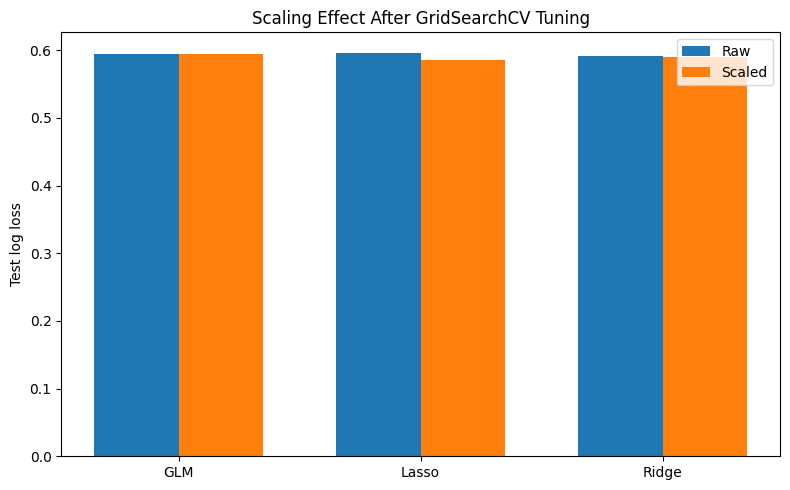

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
import statsmodels.api as sm

# ============================================================
# Adjustable settings
# ============================================================
random_state = 7
test_size = 0.30
C_grid = [0.1, 0.3, 1, 3, 10]   # GridSearchCV tunes C directly

np.random.seed(random_state)

# ============================================================
# 1) Synthetic heart-disease-style data
# ============================================================
n = 800

age = np.random.normal(loc=50, scale=9, size=n)
sbp = np.random.normal(loc=135, scale=18, size=n)
tobacco = np.random.gamma(shape=2.0, scale=1.5, size=n)
ldl = np.random.normal(loc=4.2, scale=0.8, size=n)
adiposity = np.random.normal(loc=25, scale=4.5, size=n)
obesity = np.random.normal(loc=27, scale=4.0, size=n)
alcohol = np.random.gamma(shape=1.4, scale=6.0, size=n)
family_history = np.random.binomial(1, 0.30, size=n)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

linear_part = (
    -9.0
    + 0.045 * age
    + 0.018 * sbp
    + 0.55 * tobacco
    + 0.52 * ldl
    + 0.030 * adiposity
    + 0.010 * obesity
    + 0.010 * alcohol
    + 0.95 * family_history
    + np.random.normal(scale=0.75, size=n)
)

p = sigmoid(linear_part)
chd = np.random.binomial(1, p, size=n)

features = ["age", "sbp", "tobacco", "ldl", "adiposity", "obesity", "alcohol", "family_history"]
X = pd.DataFrame({
    "age": age,
    "sbp": sbp,
    "tobacco": tobacco,
    "ldl": ldl,
    "adiposity": adiposity,
    "obesity": obesity,
    "alcohol": alcohol,
    "family_history": family_history
})
y = chd

print("Class balance:")
print(pd.Series(y).value_counts(normalize=True).rename("proportion"))

# ============================================================
# 2) Train/test split
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=random_state, stratify=y
)

# ============================================================
# 3) Unregularized model with statsmodels
# ============================================================
def fit_glm_binomial(Xtr, Xte, ytr, yte):
    Xtr_sm = sm.add_constant(Xtr, has_constant="add")
    Xte_sm = sm.add_constant(Xte, has_constant="add")
    fit = sm.GLM(ytr, Xtr_sm, family=sm.families.Binomial()).fit()
    prob = fit.predict(Xte_sm)
    pred = (prob >= 0.5).astype(int)
    return fit, accuracy_score(yte, pred), log_loss(yte, prob)

# ============================================================
# 4) GridSearchCV helpers that avoid deprecated penalty=
# ============================================================
def tune_logreg(Xtr, ytr, scale=False, l1_ratio=0.0, solver="lbfgs"):
    """
    Uses LogisticRegression without passing penalty=.
    Tune C only. l1_ratio=1.0 approximates lasso-like behavior in newer APIs.
    l1_ratio=0.0 approximates ridge-like behavior in newer APIs.
    """
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))
    clf = LogisticRegression(
        solver=solver,
        l1_ratio=l1_ratio,
        max_iter=5000
    )
    steps.append(("clf", clf))
    pipe = Pipeline(steps)

    grid = GridSearchCV(
        pipe,
        param_grid={"clf__C": C_grid},
        scoring="neg_log_loss",
        cv=5,
        n_jobs=-1
    )
    grid.fit(Xtr, ytr)
    return grid

def eval_grid(grid, Xte, yte):
    prob = grid.predict_proba(Xte)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return accuracy_score(yte, pred), log_loss(yte, prob)

# ============================================================
# 5) Fit all six cases
# ============================================================
# No scaling
glm_raw_fit, glm_raw_acc, glm_raw_ll = fit_glm_binomial(X_train, X_test, y_train, y_test)

# "Lasso-like" with l1_ratio=1.0
lasso_raw_grid = tune_logreg(X_train, y_train, scale=False, l1_ratio=1.0, solver="saga")
lasso_raw_acc, lasso_raw_ll = eval_grid(lasso_raw_grid, X_test, y_test)

# "Ridge-like" with l1_ratio=0.0
ridge_raw_grid = tune_logreg(X_train, y_train, scale=False, l1_ratio=0.0, solver="lbfgs")
ridge_raw_acc, ridge_raw_ll = eval_grid(ridge_raw_grid, X_test, y_test)

# With scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

glm_scaled_fit, glm_scaled_acc, glm_scaled_ll = fit_glm_binomial(
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

lasso_scaled_grid = tune_logreg(X_train, y_train, scale=True, l1_ratio=1.0, solver="saga")
lasso_scaled_acc, lasso_scaled_ll = eval_grid(lasso_scaled_grid, X_test, y_test)

ridge_scaled_grid = tune_logreg(X_train, y_train, scale=True, l1_ratio=0.0, solver="lbfgs")
ridge_scaled_acc, ridge_scaled_ll = eval_grid(ridge_scaled_grid, X_test, y_test)

# ============================================================
# 6) Print results
# ============================================================
print("\n================ RESULTS ================")
print(f"GLM raw:    acc={glm_raw_acc:.3f}, ll={glm_raw_ll:.3f}")
print(f"GLM scaled: acc={glm_scaled_acc:.3f}, ll={glm_scaled_ll:.3f}")

print(f"\nLasso raw:    best C={lasso_raw_grid.best_params_['clf__C']}, acc={lasso_raw_acc:.3f}, ll={lasso_raw_ll:.3f}")
print(f"Lasso scaled: best C={lasso_scaled_grid.best_params_['clf__C']}, acc={lasso_scaled_acc:.3f}, ll={lasso_scaled_ll:.3f}")

print(f"\nRidge raw:    best C={ridge_raw_grid.best_params_['clf__C']}, acc={ridge_raw_acc:.3f}, ll={ridge_raw_ll:.3f}")
print(f"Ridge scaled: best C={ridge_scaled_grid.best_params_['clf__C']}, acc={ridge_scaled_acc:.3f}, ll={ridge_scaled_ll:.3f}")

summary = pd.DataFrame([
    ["GLM", "raw", np.nan, glm_raw_acc, glm_raw_ll],
    ["GLM", "scaled", np.nan, glm_scaled_acc, glm_scaled_ll],
    ["Lasso-like", "raw", lasso_raw_grid.best_params_["clf__C"], lasso_raw_acc, lasso_raw_ll],
    ["Lasso-like", "scaled", lasso_scaled_grid.best_params_["clf__C"], lasso_scaled_acc, lasso_scaled_ll],
    ["Ridge-like", "raw", ridge_raw_grid.best_params_["clf__C"], ridge_raw_acc, ridge_raw_ll],
    ["Ridge-like", "scaled", ridge_scaled_grid.best_params_["clf__C"], ridge_scaled_acc, ridge_scaled_ll],
], columns=["method", "features", "best_C", "test_accuracy", "test_log_loss"])

print("\n================ SUMMARY TABLE ================")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}" if pd.notnull(x) else "nan"))

# ============================================================
# 7) Scaling effect on log loss
# ============================================================
comparison = pd.DataFrame([
    ["GLM", glm_raw_ll, glm_scaled_ll],
    ["Lasso-like", lasso_raw_ll, lasso_scaled_ll],
    ["Ridge-like", ridge_raw_ll, ridge_scaled_ll],
], columns=["method", "raw_log_loss", "scaled_log_loss"])
comparison["scaled_minus_raw"] = comparison["scaled_log_loss"] - comparison["raw_log_loss"]

print("\n================ LOG-LOSS CHANGE (scaled - raw) ================")
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ============================================================
# 8) Optional plot
# ============================================================
labels = ["GLM", "Lasso", "Ridge"]
raw_losses = [glm_raw_ll, lasso_raw_ll, ridge_raw_ll]
scaled_losses = [glm_scaled_ll, lasso_scaled_ll, ridge_scaled_ll]

x = np.arange(len(labels))
w = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - w/2, raw_losses, width=w, label="Raw")
plt.bar(x + w/2, scaled_losses, width=w, label="Scaled")
plt.xticks(x, labels)
plt.ylabel("Test log loss")
plt.title("Scaling Effect After GridSearchCV Tuning")
plt.legend()
plt.tight_layout()
plt.show()

Logistic regression models probabilities. SVMs approach classification differently: they focus on finding a good decision boundary. This is useful when the main goal is accurate classification rather than probability estimation.

## Story 3: Handwritten ZIP-code recognition: SVMs helped machines read messy human digits

### The real-world problem

Before online shopping, smartphone cameras, and modern deep learning, postal services had a brutally practical machine-learning problem:

> Can a machine read handwritten ZIP codes on envelopes?

Humans write digits in wildly different ways. A “2” might be curly, sharp, tilted, half-closed, or almost look like a “7.” A postal system needs to classify each digit as 0–9 quickly and accurately.

This became one of the classic proving grounds for SVMs.

## Core idea:

In spite of their similarity to logistic regression, SVMs can sometimes perform tasks that you wouldn't have thought possible with logistic regression - often using kernels.

## Why it matters:

Kernels are important when using SVMs; they allow curved boundaries as opposed to linear boundaries.

### Where the SVM idea fits

Each handwritten digit image can be treated as a point in a high-dimensional space. For example, a 16×16 grayscale digit image is already 256 features. A 28×28 image is 784 features.

The SVM tries to separate classes using a decision boundary. For a simple binary example, imagine separating:

> “Is this digit a 3 or an 8?”

The SVM looks for a hyperplane that separates the two classes with the **largest margin**.

The intuitive reason this matters is nice:

> If the boundary is barely squeezed between the training examples, it may be fragile.  
> If the boundary has a wide safety zone around it, it may generalize better to new handwriting.

The training examples closest to the boundary are the **support vectors**. In handwriting, those are the weird, ambiguous digits: the “3” that almost looks like an “8,” or the “7” that almost looks like a “1.” These borderline examples largely determine where the SVM places the boundary.

### Why kernels made this possible

Handwritten digits are not usually separable by a simple straight line in pixel space. The difference between a 3 and an 8 may involve curves, loops, stroke thickness, and spatial relationships.

This is where the **kernel trick** becomes powerful. Instead of explicitly creating millions of curved or interaction features, the SVM can use a kernel to behave as if it were separating the data in a richer feature space.

For digit recognition, researchers used kernels such as polynomial kernels and Gaussian/RBF-style kernels to create nonlinear decision boundaries.

In intuitive terms:

> A linear SVM says, “Can I separate these digits with a flat wall?”  
> A kernel SVM says, “What if I could bend the wall around the complicated shapes?”

### Sources

Cortes, C., & Vapnik, V. “Support-Vector Networks.” *Machine Learning*, 1995.  
https://doi.org/10.1007/BF00994018

LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. “Gradient-Based Learning Applied to Document Recognition.” *Proceedings of the IEEE*, 1998.  
https://doi.org/10.1109/5.726791

DeCoste, D., & Schölkopf, B. “Training Invariant Support Vector Machines.” *Machine Learning*, 2002.  
https://doi.org/10.1023/A:1012454411458

## Data:

SVMs acting on MNIST digits.

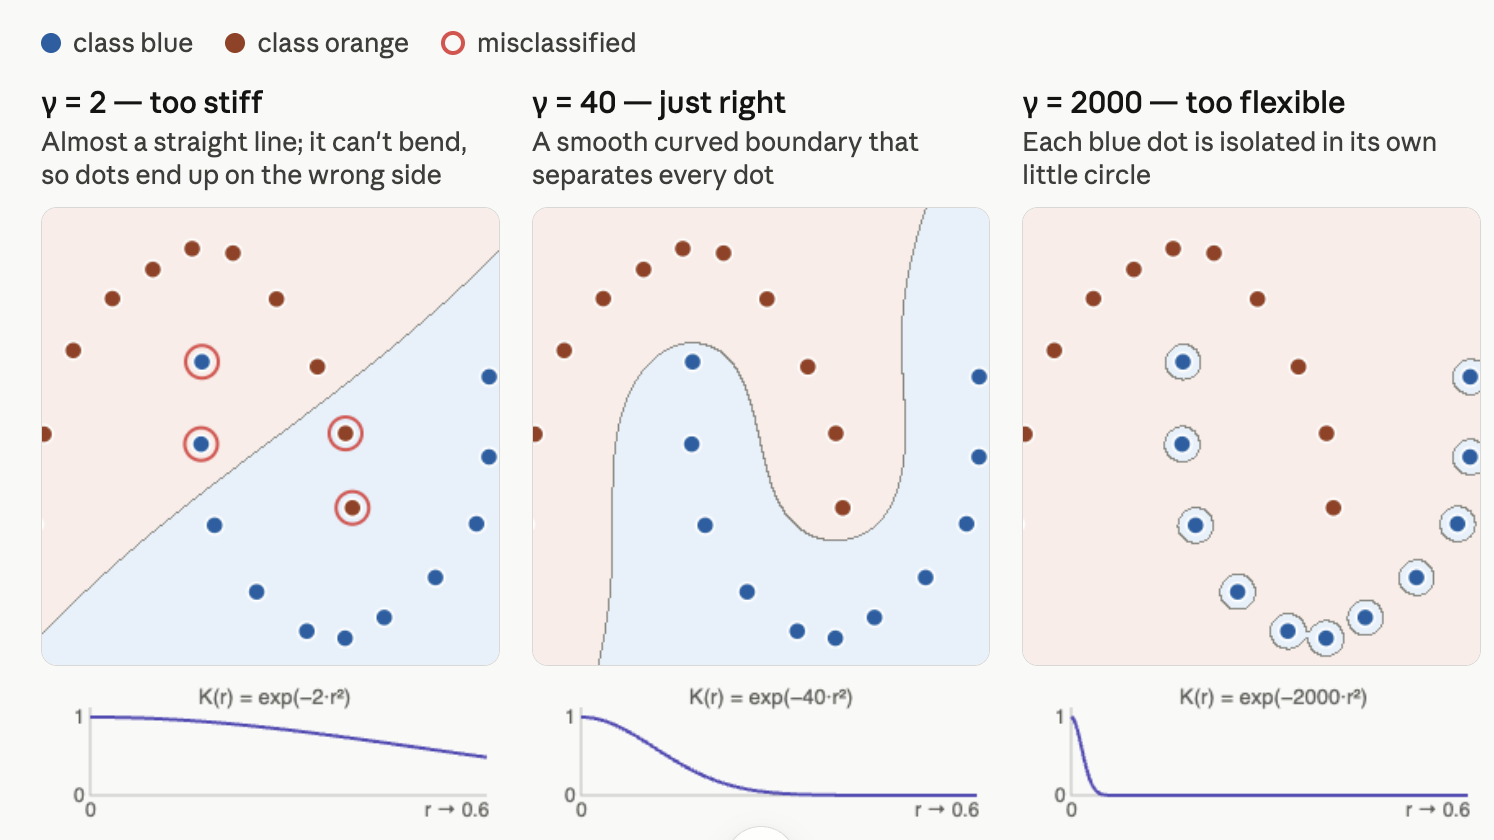

In [41]:
from IPython.display import Image, display

display(Image(filename="Screenshot 3.png"))

Train shape: (8000, 784)
Test shape: (2000, 784)


/Users/vonkorff/jupyter-classic/lib/python3.13/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



=== Linear SVM ===
Training time: 333.40 sec
Accuracy: 0.8530
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       197
           1       0.89      0.94      0.92       225
           2       0.83      0.84      0.84       200
           3       0.80      0.76      0.78       204
           4       0.92      0.87      0.89       195
           5       0.81      0.79      0.80       180
           6       0.89      0.92      0.91       197
           7       0.80      0.87      0.83       208
           8       0.86      0.73      0.79       195
           9       0.83      0.83      0.83       199

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000


=== RBF Kernel SVM ===
Training time: 2.51 sec
Accuracy: 0.9480
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       197
    

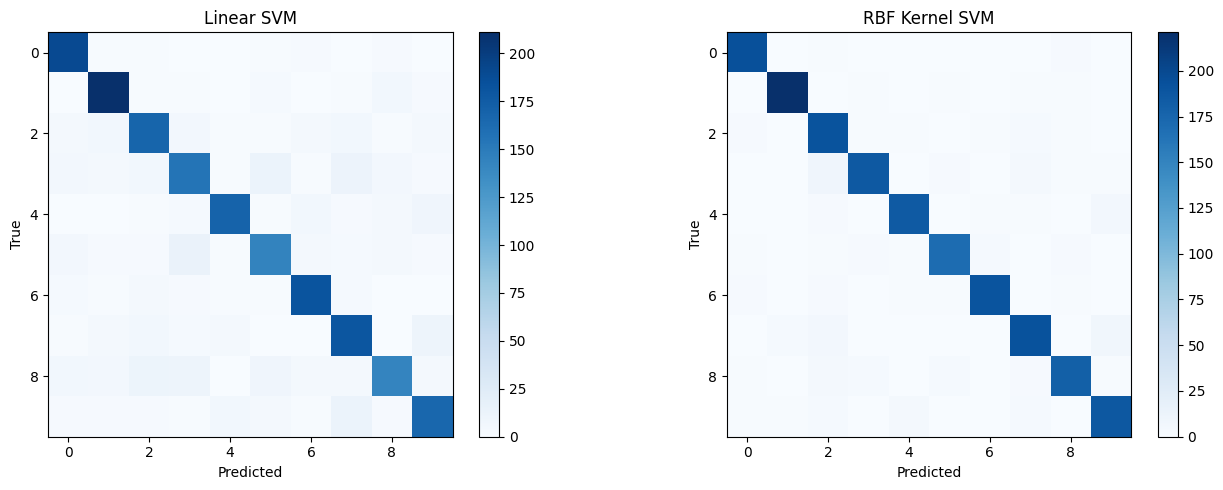

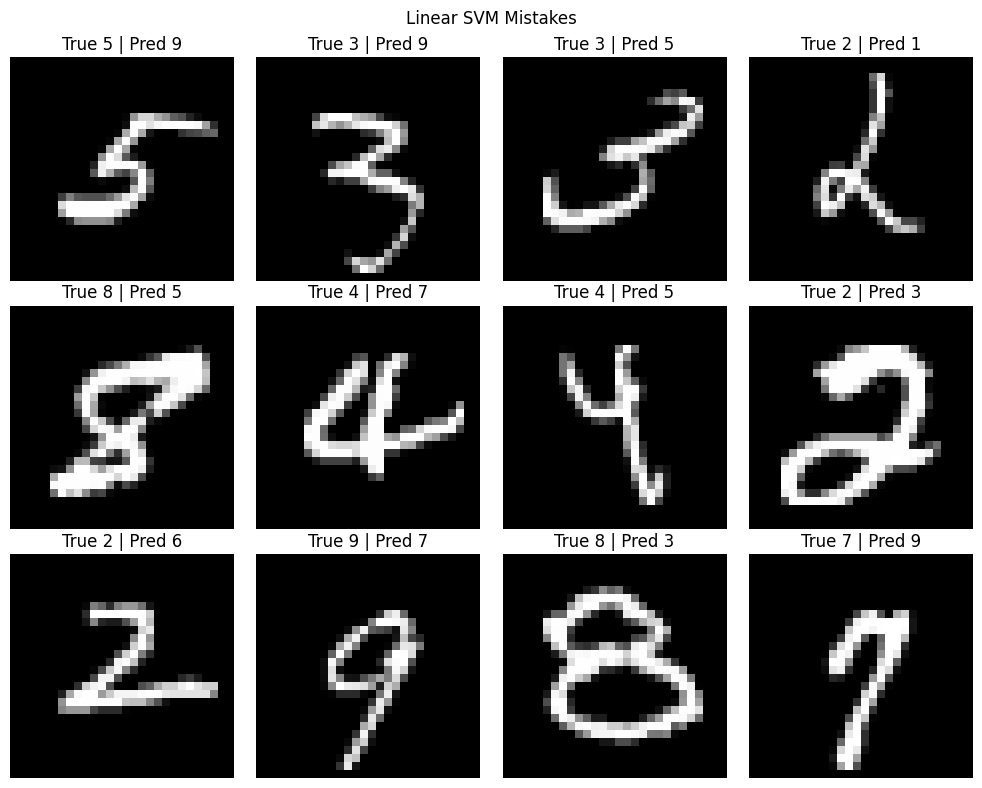

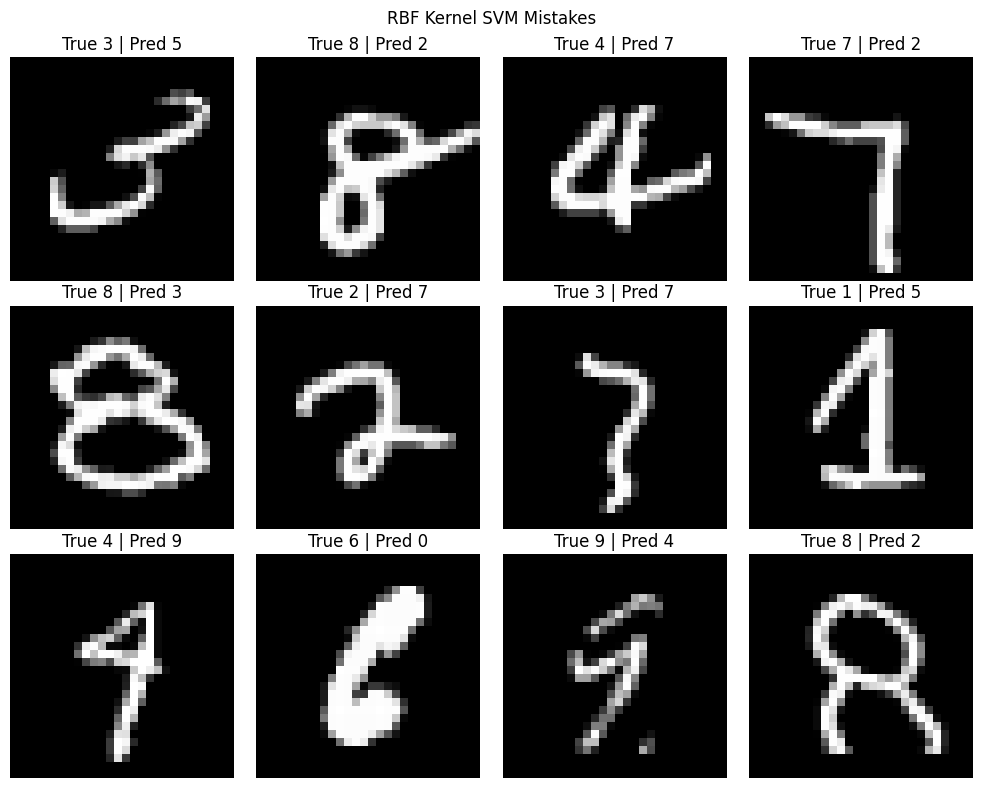

In [33]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ----------------------------
# 1) Load MNIST
# ----------------------------
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(str)

# Use a smaller subset so the kernel SVM can finish in a reasonable time.
# Increase these if you want better performance and have more compute.
n_train = 8000
n_test = 2000

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X, y, test_size=n_test, random_state=42, stratify=y
)

X_train = X_train_full[:n_train]
y_train = y_train_full[:n_train]
X_test = X_test_full
y_test = y_test_full

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

# ----------------------------
# 2) Linear SVM (no kernel trick)
# ----------------------------
linear_model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=42)
)

t0 = time.time()
linear_model.fit(X_train, y_train)
linear_time = time.time() - t0

y_pred_linear = linear_model.predict(X_test)
linear_acc = accuracy_score(y_test, y_pred_linear)

print("\n=== Linear SVM ===")
print(f"Training time: {linear_time:.2f} sec")
print(f"Accuracy: {linear_acc:.4f}")
print(classification_report(y_test, y_pred_linear))

# ----------------------------
# 3) Kernel SVM (RBF kernel trick)
# ----------------------------
# Note: this is much slower than LinearSVC, especially on large datasets.
# We use a smaller training set for practicality.
kernel_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=5.0, gamma="scale")
)

t0 = time.time()
kernel_model.fit(X_train, y_train)
kernel_time = time.time() - t0

y_pred_kernel = kernel_model.predict(X_test)
kernel_acc = accuracy_score(y_test, y_pred_kernel)

print("\n=== RBF Kernel SVM ===")
print(f"Training time: {kernel_time:.2f} sec")
print(f"Accuracy: {kernel_acc:.4f}")
print(classification_report(y_test, y_pred_kernel))

# ----------------------------
# 4) Confusion matrices
# ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], confusion_matrix(y_test, y_pred_linear), "Linear SVM"),
    (axes[1], confusion_matrix(y_test, y_pred_kernel), "RBF Kernel SVM"),
]:
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# ----------------------------
# 5) Show a few mistakes
# ----------------------------
def show_mistakes(X_test, y_test, y_pred, title, n=12):
    mistakes = np.where(y_test != y_pred)[0]
    if len(mistakes) == 0:
        print(f"No mistakes found for {title}.")
        return

    idx = mistakes[:n]
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    axes = axes.ravel()

    for i, ax in zip(idx, axes):
        ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
        ax.set_title(f"True {y_test[i]} | Pred {y_pred[i]}")
        ax.axis("off")

    for ax in axes[len(idx):]:
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_mistakes(X_test, y_test, y_pred_linear, "Linear SVM Mistakes")
show_mistakes(X_test, y_test, y_pred_kernel, "RBF Kernel SVM Mistakes")